# YOLO11n + MobileNetV3-Small 中心凹坐标偏移回归

自包含 Kaggle Notebook：已有 YOLO 五折 OOF → MobileNet 五折验证 → 全量精修训练 → 单个已有 YOLO + 全量精修器生成提交。

**全量的含义：**排除完全重复的 `0077.jpg`，使用全部 **79 张不同训练图**训练一个新的精修器。第一阶段不重训，最终手动指定已有的一折 YOLO，不融合；该 YOLO 只见过其训练折约 63 张图。此流程不能称为“两阶段都全量重训”。

需要添加两个 Kaggle Input：原始比赛数据；第一阶段目录下的 `config.json`、`environment.json`、`fold_assignments.csv`、`oof_predictions.csv` 和五个 `fold_*_best.pt`。不需要旧 U-Net 权重、prepared 图或 YOLO 通用初始权重。

训练裁剪只用当前训练折 GT 加扰动，不用全数据五折 OOF 来构造训练输入，避免间接引入外层验证信息。验证使用对应折真实 YOLO OOF，低置信度/无检测时使用全局眼底输入。所有样本计入完整链路 RMSE。

这是待 Kaggle 实验的新方案，不保证优于旧热力图模型。参考：[MobileNetV3-Small 官方文档](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html)。

In [1]:
# ==================== 所有路径与运行开关：只需先修改这里 ====================
# 
from pathlib import Path
DATA_DIR = Path('/kaggle/input/competitions/2026task3/detection')
STAGE1_DIR = Path('/kaggle/input/models/guanyliu/yolo/pytorch/default/1/yolo')
OUTPUT_ROOT = Path('/kaggle/working/fovea_mobilenet_offset')
MOBILENET_WEIGHTS = None  # None: 下载官方 ImageNet 权重；离线填官方 .pth 路径

RUN_CV = True
RUN_FULL_TRAIN = True
RUN_SUBMISSION = True
# 重开内核、不重跑 CV：填已有新模型 CV 结果目录（含 fold_metrics.csv、config.json）。
CV_RESULTS_DIR = None
# 只生成提交：两个训练开关均 False，并填写已有 full_model.pth。
FINAL_REFINER_PATH = None
FINAL_YOLO_FOLD = 1  # 预先固定，不能因某折验证分低就认定它在测试集最好

CFG = dict(seed=42, input_size=256, batch_size=8, workers=2, device='cuda', amp=True,
           folds_to_run=[1,2,3,4,5], epochs=100, warmup_epochs=3, patience=20,
           repeats_per_epoch=4, backbone_lr=1e-5, head_lr=3e-4, weight_decay=1e-4,
           freeze_bn=True, gradient_clip=5.0, loss_scale_px=1000.0,
           dropout=0.1, low_confidence_threshold=0.01,
           global_probability=0.20, small_jitter=0.07, large_jitter=0.25,
           large_jitter_probability=0.20, scale_min=0.8, scale_max=1.25)
EXCLUDE_FILES = {'0077.jpg'}
# 默认用完整五折最佳 epoch 的中位数。只有明确进行新实验时才手动覆盖。
FULL_EPOCHS_OVERRIDE = None
EXPECTED_TEST_COUNT = 20
# Windows 本地：workers=0；CPU：device='cpu', amp=False。


## Epoch 如何确定

1. 在五折中各自按**完整链路原图坐标 RMSE**保存精修器最佳 epoch，早停只控制运行时长。
2. 取五个最佳 epoch 的中位数，例如 `[12, 20, 16, 30, 18] → 18`。这是稳健的训练时长启发式，不保证全量数据的真正最优轮次。
3. 从同样的 ImageNet 权重重新初始化，在 79 张图上固定训练 18 个 epoch，保存**第 18 轮**，不根据全量训练损失挑“最佳模型”，不查看测试标签。

CV 与全量训练保持每张图每轮 4 个随机视图、相同预热和学习率时间表。学习率衰减始终以 `CFG['epochs']` 为基准，全量训练截取同一时间表的前若干轮，不压缩余弦周期。全量数据每轮更新次数略增，因此该规则仍是近似；不额外乘 79/63。

局部裁剪以 GT 为中心：大多数为小偏移，部分为较大偏移；20% 输入为全局眼底，覆盖低置信度回退。阈值 0.01 沿用旧实验，为探索性参数。全局输入的回归难度较大，需要单独查看它的指标。

In [2]:
import importlib.util, subprocess, sys
from importlib.metadata import version
# 保留 Kaggle 自带的匹配 torch/torchvision，不自动替换 CUDA 环境。
for module in ('torch','torchvision'):
    if importlib.util.find_spec(module) is None:
        raise RuntimeError('请在 Kaggle 开启 GPU，并使用匹配的 torch / torchvision。')
packages = {'numpy':'numpy','pandas':'pandas','PIL':'pillow','scipy':'scipy',
            'sklearn':'scikit-learn','matplotlib':'matplotlib',
            'ultralytics':'ultralytics==8.4.189'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.4 MB/s  0:00:00



In [3]:
import gc, hashlib, json, math, random, re, uuid
from datetime import datetime
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import functional as TF
from ultralytics import YOLO
from IPython.display import display

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')

def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True

def metrics(frame, x='final_x', y='final_y'):
    if not len(frame): return {'n':0}
    error=frame[[x,y]].to_numpy(float)-frame[['true_x','true_y']].to_numpy(float)
    assert np.isfinite(error).all()
    d=np.linalg.norm(error,axis=1)
    return dict(n=len(frame),rmse_px=float(np.sqrt(np.mean(error**2))),
                x_rmse_px=float(np.sqrt(np.mean(error[:,0]**2))),
                y_rmse_px=float(np.sqrt(np.mean(error[:,1]**2))),
                median_distance_px=float(np.median(d)),mean_distance_px=float(d.mean()),
                max_distance_px=float(d.max()))

assert CFG['input_size']%32==0 and CFG['epochs']>CFG['warmup_epochs']
assert 0<=CFG['global_probability']<=1 and 0<=CFG['large_jitter_probability']<=1
assert 0<=CFG['small_jitter']<=CFG['large_jitter']<0.45
assert 0<CFG['scale_min']<=CFG['scale_max']
assert 1<=FINAL_YOLO_FOLD<=5
device=torch.device(CFG['device'])
if device.type=='cuda' and not torch.cuda.is_available(): raise RuntimeError('请开启 GPU，或配置 CPU。')
use_amp=bool(CFG['amp'] and device.type=='cuda')
for name in ('config.json','environment.json','fold_assignments.csv','oof_predictions.csv'):
    if not (STAGE1_DIR/name).is_file(): raise FileNotFoundError(STAGE1_DIR/name)
s1_config=json.loads((STAGE1_DIR/'config.json').read_text(encoding='utf-8'))
s1_environment=json.loads((STAGE1_DIR/'environment.json').read_text(encoding='utf-8'))
assert s1_config['excluded_files']==sorted(EXCLUDE_FILES)
print('旧/当前 ultralytics:',s1_environment.get('packages',{}).get('ultralytics'),version('ultralytics'))
if s1_environment.get('packages',{}).get('ultralytics')!=version('ultralytics'):
    print('版本不同：建议使用旧 environment.json 中的版本，安装后重启内核。')
RUN_DIR=OUTPUT_ROOT/(datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:6])
RUN_DIR.mkdir(parents=True,exist_ok=False)
save_json(RUN_DIR/'config.json',dict(cfg=CFG,stage1=s1_config,excluded_files=sorted(EXCLUDE_FILES),
    model='MobileNetV3SmallSpatialOffset',data_dir=str(DATA_DIR),stage1_dir=str(STAGE1_DIR),
    final_yolo_fold=FINAL_YOLO_FOLD,full_training_scope='refiner only; frozen existing YOLO',
    pretrained=str(MOBILENET_WEIGHTS) if MOBILENET_WEIGHTS else 'IMAGENET1K_V1'))
save_json(RUN_DIR/'environment.json',dict(python=sys.version,torch=str(torch.__version__),
    torchvision=version('torchvision'),ultralytics=version('ultralytics'),
    gpu=torch.cuda.get_device_name(device) if device.type=='cuda' else None))
print('本次输出:',RUN_DIR)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
旧/当前 ultralytics: 8.4.189 8.4.189
本次输出: /kaggle/working/fovea_mobilenet_offset/20261027_073418_6fe955


In [5]:
from scipy import ndimage

def detect_fundus_square(image, settings):
    """仅依赖图像；返回可超出原图的外接正方形，不参考任何标注。"""
    width, height = image.size
    thumbnail = image.copy()
    maximum = settings['detection_max_size']
    thumbnail.thumbnail((maximum, maximum), Image.Resampling.BILINEAR)
    array = np.asarray(thumbnail)
    mask = array.max(axis=2) > settings['foreground_threshold']
    labels, count = ndimage.label(mask, structure=np.ones((3, 3)))
    fallback_reason = ''
    if count == 0:
        fallback_reason = 'no_foreground'
    else:
        sizes = np.bincount(labels.ravel())
        sizes[0] = 0
        largest_id = int(sizes.argmax())
        component = labels == largest_id
        component_fraction = float(component.mean())
        coverage = float(component.sum() / max(1, mask.sum()))
        if component_fraction < settings['min_component_fraction']:
            fallback_reason = 'foreground_too_small'
        elif coverage < settings['min_component_coverage']:
            fallback_reason = 'fragmented_foreground'
        else:
            ys, xs = np.where(component)
            x0 = int(np.floor(xs.min() * width / thumbnail.width))
            y0 = int(np.floor(ys.min() * height / thumbnail.height))
            x1 = int(np.ceil((xs.max() + 1) * width / thumbnail.width))
            y1 = int(np.ceil((ys.max() + 1) * height / thumbnail.height))
            side = int(np.ceil(max(x1 - x0, y1 - y0) * (1 + 2 * settings['margin_fraction'])))
            left = int(np.floor((x0 + x1 - side) / 2))
            top = int(np.floor((y0 + y1 - side) / 2))

    if fallback_reason:
        side = max(width, height)
        left, top = (width - side) // 2, (height - side) // 2

    # 在原分辨率检查：缩略图检测是否遗漏了明显的非黑区域。
    foreground = np.asarray(image).max(axis=2) > settings['foreground_threshold']
    total_foreground = int(foreground.sum())
    retained = int(foreground[max(0, top):min(height, top + side),
                              max(0, left):min(width, left + side)].sum())
    retained_fraction = retained / total_foreground if total_foreground else 1.0
    if retained_fraction < settings['min_retained_foreground']:
        fallback_reason = 'low_full_resolution_retention'
        side = max(width, height)
        left, top = (width - side) // 2, (height - side) // 2
        retained_fraction = 1.0
    return {'crop_left': left, 'crop_top': top, 'crop_side': side,
            'crop_status': 'fallback_full_image' if fallback_reason else 'fundus_square',
            'crop_fallback_reason': fallback_reason,
            'retained_foreground_fraction': retained_fraction}


In [6]:
def load_manifest():
    frame=pd.read_csv(STAGE1_DIR/'oof_predictions.csv').sort_values('filename').reset_index(drop=True)
    required={'filename','image_id','fold','width','height','true_x','true_y','file_sha256',
              'xmin','ymin','xmax','ymax','crop_left','crop_top','crop_side',
              'pred_x','pred_y','detected','confidence','roi_left','roi_top','roi_right','roi_bottom'}
    assert required.issubset(frame.columns), required-set(frame.columns)
    assert len(frame)==79 and not frame.filename.duplicated().any() and not frame.image_id.duplicated().any()
    files={p.name:p for p in (DATA_DIR/'train').iterdir()
           if p.suffix.lower() in {'.jpg','.jpeg','.png'} and p.name not in EXCLUDE_FILES}
    assert set(files)==set(frame.filename)
    gt=pd.read_csv(DATA_DIR/'fovea_localization_train_GT.csv')
    ids=pd.to_numeric(gt['data'],errors='raise')
    assert np.isfinite(ids).all() and (ids==ids.astype(int)).all()
    gt['id']=ids.astype(int); assert not gt.id.duplicated().any()
    gt=gt.set_index('id')
    assert set(gt.index)==set(frame.image_id)|{int(Path(f).stem) for f in EXCLUDE_FILES}
    assignments=pd.read_csv(STAGE1_DIR/'fold_assignments.csv').set_index('filename')
    assert assignments.index.is_unique and set(assignments.index)==set(frame.filename)
    assert np.array_equal(assignments.loc[frame.filename,'fold'].to_numpy(),frame.fold.to_numpy())
    expected=np.zeros(len(frame),int)
    for fold,(_,vi) in enumerate(KFold(5,shuffle=True,random_state=s1_config['cfg']['seed']).split(frame),1):
        expected[vi]=fold
    assert np.array_equal(expected,frame.fold.to_numpy()),'OOF 划分不一致'
    bools=frame.detected.astype(str).str.lower()
    assert bools.isin(['true','false','1','0']).all()
    frame['detected']=bools.isin(['true','1'])
    assert np.isfinite(frame.loc[frame.detected,'confidence']).all()
    numeric=['true_x','true_y','pred_x','pred_y','crop_left','crop_top','crop_side',
             'roi_left','roi_top','roi_right','roi_bottom','xmin','ymin','xmax','ymax']
    assert np.isfinite(frame[numeric].to_numpy(float)).all()
    assert ((frame.xmax>frame.xmin)&(frame.ymax>frame.ymin)&(frame.crop_side>0)).all()
    assert ((frame.roi_right-frame.roi_left)==(frame.roi_bottom-frame.roi_top)).all()
    assert (frame.roi_right>frame.roi_left).all()
    paths=[]
    for r in frame.itertuples(index=False):
        p=files[r.filename]; assert int(p.stem)==r.image_id
        assert sha256(p)==r.file_sha256, r.filename
        assert np.allclose(gt.loc[r.image_id,['Fovea_X','Fovea_Y']].to_numpy(float),
                           [r.true_x,r.true_y],rtol=0,atol=1e-6)
        with Image.open(p) as im:
            im=im.convert('RGB'); assert im.size==(r.width,r.height)
            crop=detect_fundus_square(im,s1_config['crop_cfg'])
        for k in ('crop_left','crop_top','crop_side'): assert crop[k]==getattr(r,k),(r.filename,k)
        assert 0<=r.true_x<r.width and 0<=r.true_y<r.height
        paths.append(str(p.resolve()))
    frame['path']=paths
    return frame

df=load_manifest()
df.to_csv(RUN_DIR/'stage1_inputs.csv',index=False)
print('第一阶段总体 OOF:',metrics(df,'pred_x','pred_y'))
display(df.groupby('fold').size().rename('validation_n').to_frame())


第一阶段总体 OOF: {'n': 79, 'rmse_px': 58.798872980508484, 'x_rmse_px': 78.04151122179304, 'y_rmse_px': 28.707794303545732, 'median_distance_px': 8.244175906980356, 'mean_distance_px': 23.852306773782484, 'max_distance_px': 709.0989122190372}


,validation_n
fold,
1,16
2,16
3,16
4,16
5,15


## 裁剪、偏移坐标和网络

`offset_x = (X-left+0.5)/side - 0.5`，Y 同理；逆变换为 `X = (offset_x+0.5)*side-0.5+left`。
水平翻转同步执行 `offset_x = -offset_x`。裁剪超出原图补黑；不通过验证 GT 调整窗口。

使用 MobileNetV3-Small 的预训练 features，保留 `4×4` 空间网格，再接小回归头输出两个偏移。保留空间网格是为了提供位置线索；没有 U-Net 解码器。`0.5*tanh` 将坐标约束在输入窗口内，所以窗口漏出目标时第二阶段无法恢复，必须将该样本计入失败。

训练损失为原图像素 MSE / 1000²，各种大小窗口与不同分辨率图片按比赛坐标误差一致加权。正常训练窗口多数小扰动，偶尔大扰动；无训练折 OOF 输入。全局/局部共用回归器是简单基线，需要比较回退子集效果。

In [8]:
def point_to_offset(x,y,left,top,side):
    return np.array([(x-left+0.5)/side-0.5,(y-top+0.5)/side-0.5],dtype=np.float32)

def offset_to_point(offset,left,top,side):
    return (np.asarray(offset,dtype=np.float64)+0.5)*side-0.5+np.array([left,top])

def typical_fraction(frame):
    return float(np.median(np.maximum(frame.xmax-frame.xmin,frame.ymax-frame.ymin)/frame.crop_side))

def train_roi(row,fraction):
    if np.random.random()<CFG['global_probability']:
        return int(row.crop_left),int(row.crop_top),int(row.crop_side)
    roi=s1_config['roi_cfg']
    base=max(roi['expansion']*fraction*row.crop_side,roi['min_side_fraction']*row.crop_side)
    side=int(np.ceil(base*np.random.uniform(CFG['scale_min'],CFG['scale_max'])))
    jitter=CFG['large_jitter'] if np.random.random()<CFG['large_jitter_probability'] else CFG['small_jitter']
    delta=np.random.uniform(-jitter,jitter,2)*side
    center=np.array([row.true_x,row.true_y])+delta
    return int(np.floor(center[0]-side/2)),int(np.floor(center[1]-side/2)),side

def eval_plan(frame):
    out=frame.copy()
    weak=(~out.detected)|(out.confidence<CFG['low_confidence_threshold'])
    out['eval_left']=np.where(weak,out.crop_left,out.roi_left).astype(int)
    out['eval_top']=np.where(weak,out.crop_top,out.roi_top).astype(int)
    out['eval_side']=np.where(weak,out.crop_side,out.roi_right-out.roi_left).astype(int)
    out['eval_mode']=np.where(weak,'global_fallback','local_detection')
    if 'true_x' in out:
        out['eval_target_inside']=((out.true_x>=out.eval_left)&(out.true_x<out.eval_left+out.eval_side)&
                                   (out.true_y>=out.eval_top)&(out.true_y<out.eval_top+out.eval_side))
    return out

def tile_tensor(image,left,top,side,augment=None):
    tile=image.crop((left,top,left+side,top+side)).resize((CFG['input_size'],CFG['input_size']),Image.Resampling.BILINEAR)
    if augment is not None: tile=augment(tile)
    return TF.normalize(TF.to_tensor(tile),[.485,.456,.406],[.229,.224,.225])

class TrainDataset(Dataset):
    def __init__(self,frame):
        self.rows=list(frame.itertuples(index=False)); self.fraction=typical_fraction(frame)
        self.colors=transforms.ColorJitter(.2,.2,.1,.01)
    def __len__(self): return len(self.rows)*CFG['repeats_per_epoch']
    def __getitem__(self,index):
        r=self.rows[index%len(self.rows)]; left,top,side=train_roi(r,self.fraction)
        target=point_to_offset(r.true_x,r.true_y,left,top,side)
        assert np.all(np.abs(target)<.5),r.filename
        with Image.open(r.path) as im:
            tile=im.convert('RGB').crop((left,top,left+side,top+side))
        if np.random.random()<.5:
            tile=tile.transpose(Image.Transpose.FLIP_LEFT_RIGHT); target[0]=-target[0]
        x=tile_tensor(tile,0,0,side,self.colors)
        return x,torch.from_numpy(target),torch.tensor(side,dtype=torch.float32)

class EvalDataset(Dataset):
    def __init__(self,plan): self.rows=list(plan.itertuples(index=False))
    def __len__(self): return len(self.rows)
    def __getitem__(self,index):
        r=self.rows[index]
        with Image.open(r.path) as im: x=tile_tensor(im.convert('RGB'),r.eval_left,r.eval_top,r.eval_side)
        return x,index

def seed_worker(_):
    seed=torch.initial_seed()%2**32; np.random.seed(seed); random.seed(seed)

def loader(dataset,shuffle,seed):
    return DataLoader(dataset,batch_size=CFG['batch_size'],shuffle=shuffle,num_workers=CFG['workers'],
        worker_init_fn=seed_worker,generator=torch.Generator().manual_seed(seed),
        pin_memory=device.type=='cuda',drop_last=False)

class MobileNetOffset(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__()
        if pretrained and MOBILENET_WEIGHTS is None:
            base=models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        else:
            base=models.mobilenet_v3_small(weights=None)
            if pretrained:
                base.load_state_dict(torch.load(MOBILENET_WEIGHTS,map_location='cpu',weights_only=True),strict=True)
        self.features=base.features
        self.head=nn.Sequential(nn.AdaptiveAvgPool2d((4,4)),nn.Flatten(),
            nn.Linear(576*4*4,128),nn.ReLU(inplace=True),nn.Dropout(CFG['dropout']),nn.Linear(128,2))
        # 初始预测靠近窗口中心，但不令所有前层完全零梯度。
        nn.init.normal_(self.head[-1].weight,std=.001); nn.init.zeros_(self.head[-1].bias)
    def forward(self,x): return .5*torch.tanh(self.head(self.features(x)))
    def train(self,mode=True):
        super().train(mode)
        if mode and CFG['freeze_bn']:
            for m in self.features.modules():
                if isinstance(m,nn.BatchNorm2d): m.eval()
        return self

@torch.no_grad()
def evaluate(model,plan):
    model.eval(); out=plan.copy().reset_index(drop=True); results=np.full((len(out),2),np.nan)
    seen=np.zeros(len(out),int)
    for images,indices in loader(EvalDataset(out),False,CFG['seed']):
        offsets=model(images.to(device).float()).cpu().numpy()
        for offset,index in zip(offsets,indices.tolist()):
            r=out.iloc[index]; xy=offset_to_point(offset,r.eval_left,r.eval_top,r.eval_side)
            results[index]=np.clip(xy,[0,0],[r.width-1,r.height-1]); seen[index]+=1
    assert (seen==1).all() and np.isfinite(results).all()
    out['final_x']=results[:,0]; out['final_y']=results[:,1]
    return out

plan=eval_plan(df)
plan.to_csv(RUN_DIR/'validation_roi_plan.csv',index=False)
print('验证输入:',plan.eval_mode.value_counts().to_dict(),'目标在输入内:',int(plan.eval_target_inside.sum()),'/',len(plan))
for r in df.itertuples(index=False):
    z=point_to_offset(r.true_x,r.true_y,r.crop_left,r.crop_top,r.crop_side)
    assert np.allclose(offset_to_point(z,r.crop_left,r.crop_top,r.crop_side),[r.true_x,r.true_y],atol=0.001,rtol=0)


验证输入: {'local_detection': 77, 'global_fallback': 2} 目标在输入内: 79 / 79


In [9]:
def save_checkpoint(path,model,epoch,fold,scope):
    torch.save(dict(model_name='MobileNetV3SmallSpatialOffset',model_state=model.state_dict(),
        epoch=int(epoch),fold=fold,scope=scope,cfg=dict(CFG),stage1_config=s1_config,
        excluded_files=sorted(EXCLUDE_FILES)),path)

def fit(train_frame,epochs,seed,out_dir,val_plan=None,fold=None):
    seed_all(seed); out_dir.mkdir(parents=True,exist_ok=False)
    model=MobileNetOffset(pretrained=True).to(device)
    print('参数量:',sum(p.numel() for p in model.parameters()))
    optimizer=torch.optim.AdamW([{'params':model.features.parameters(),'lr':CFG['backbone_lr']},
                                {'params':model.head.parameters(),'lr':CFG['head_lr']}],weight_decay=CFG['weight_decay'])
    scaler=torch.amp.GradScaler('cuda',enabled=use_amp)
    train_loader=loader(TrainDataset(train_frame),True,seed)
    best=float('inf'); best_epoch=0; stale=0; history=[]; best_predictions=None
    for epoch in range(1,epochs+1):
        # CV 和全量使用相同的学习率时间表前缀；不使用验证驱动 scheduler。
        factor=.1+.9*(1+math.cos(math.pi*(epoch-1)/CFG['epochs']))/2
        for group,base in zip(optimizer.param_groups,[CFG['backbone_lr'],CFG['head_lr']]): group['lr']=base*factor
        for p in model.features.parameters(): p.requires_grad_(epoch>CFG['warmup_epochs'])
        model.train(); total=0.; count=0
        for images,target,side in train_loader:
            images=images.to(device); target=target.to(device); side=side.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type,enabled=use_amp): pred=model(images)
            error=(pred.float()-target.float())*side[:,None]/CFG['loss_scale_px']
            loss=error.square().mean()
            if not torch.isfinite(loss): raise RuntimeError('非有限训练损失')
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(),CFG['gradient_clip'])
            scaler.step(optimizer); scaler.update()
            total+=loss.item()*len(images); count+=len(images)
        record=dict(epoch=epoch,augmented_train_rmse_px=math.sqrt(total/count)*CFG['loss_scale_px'],
                    backbone_lr=optimizer.param_groups[0]['lr'],head_lr=optimizer.param_groups[1]['lr'])
        if val_plan is not None:
            prediction=evaluate(model,val_plan); score=metrics(prediction)['rmse_px']; record['val_rmse_px']=score
            if score<best:
                best=score; best_epoch=epoch; stale=0; best_predictions=prediction
                save_checkpoint(out_dir/'best.pth',model,epoch,fold,'outer_fold_training')
                prediction.to_csv(out_dir/'best_oof_predictions.csv',index=False)
            else: stale+=1
        history.append(record); pd.DataFrame(history).to_csv(out_dir/'training_history.csv',index=False)
        print(f'epoch {epoch}/{epochs} train(aug)={record["augmented_train_rmse_px"]:.2f}',
              f'val={record["val_rmse_px"]:.2f} best_epoch={best_epoch}' if val_plan is not None else 'full training')
        if val_plan is not None and stale>=CFG['patience']: break
    if val_plan is None: save_checkpoint(out_dir/'full_model.pth',model,epochs,None,'all_79_unique_training_images')
    del model,optimizer,scaler,train_loader; gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()
    return best_epoch,best_predictions


## 五折验证

每折独立从 ImageNet 初始化。验证框由未用该图训练的 YOLO 产生。按原图坐标 RMSE 选精修器 checkpoint。
五折验证参与 epoch 选择，因此属于选模成绩；整体 OOF 由所有逐图预测计算，不能对五个 RMSE 取算术平均。

In [10]:
cv_dir=Path(CV_RESULTS_DIR) if CV_RESULTS_DIR is not None else RUN_DIR/'cv'
if RUN_CV:
    cv_dir=RUN_DIR/'cv'; cv_dir.mkdir()
    save_json(cv_dir/'config.json',dict(cfg=CFG,stage1=s1_config))
    assert len(CFG['folds_to_run'])==len(set(CFG['folds_to_run']))
    assert set(CFG['folds_to_run']).issubset({1,2,3,4,5}) and CFG['folds_to_run']
    records=[]; predictions=[]
    for fold in CFG['folds_to_run']:
        train=df[df.fold!=fold].copy(); validation=eval_plan(df[df.fold==fold].copy())
        assert set(train.filename).isdisjoint(validation.filename)
        best_epoch,pred=fit(train,CFG['epochs'],CFG['seed']+fold,cv_dir/f'fold_{fold}',validation,fold)
        predictions.append(pred)
        records.append(dict(fold=fold,train_n=len(train),val_n=len(validation),best_epoch=best_epoch,
                            coarse_rmse_px=metrics(pred,'pred_x','pred_y')['rmse_px'],**metrics(pred)))
        pd.DataFrame(records).to_csv(cv_dir/'fold_metrics.csv',index=False)
        pd.concat(predictions,ignore_index=True).to_csv(cv_dir/'oof_predictions.csv',index=False)
    oof=pd.concat(predictions,ignore_index=True).sort_values('filename')
    summary=dict(complete_five_fold_oof=set(CFG['folds_to_run'])=={1,2,3,4,5},
        coarse=metrics(oof,'pred_x','pred_y'),refined=metrics(oof),
        local=metrics(oof[oof.eval_mode=='local_detection']),
        global_fallback=metrics(oof[oof.eval_mode=='global_fallback']),
        outside_n=int((~oof.eval_target_inside).sum()))
    save_json(cv_dir/'cv_summary.json',summary)
    print(json.dumps(summary,ensure_ascii=False,indent=2)); display(pd.DataFrame(records))
    error=np.hypot(oof.final_x-oof.true_x,oof.final_y-oof.true_y)
    oof.assign(euclidean_error_px=error).sort_values('euclidean_error_px',ascending=False).to_csv(cv_dir/'ranked_errors.csv',index=False)
else:
    print('跳过 CV；若要全量训练，需填写 CV_RESULTS_DIR 或显式指定 FULL_EPOCHS_OVERRIDE。')


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 102MB/s]


参数量: 2107042
epoch 1/100 train(aug)=57.89 val=15.99 best_epoch=1
epoch 2/100 train(aug)=42.74 val=18.29 best_epoch=1
epoch 3/100 train(aug)=34.72 val=15.29 best_epoch=3
epoch 4/100 train(aug)=45.00 val=16.23 best_epoch=3
epoch 5/100 train(aug)=35.31 val=19.19 best_epoch=3
epoch 6/100 train(aug)=30.87 val=16.51 best_epoch=3
epoch 7/100 train(aug)=26.66 val=16.37 best_epoch=3
epoch 8/100 train(aug)=30.91 val=14.30 best_epoch=8
epoch 9/100 train(aug)=28.14 val=13.97 best_epoch=9
epoch 10/100 train(aug)=25.05 val=13.52 best_epoch=10
epoch 11/100 train(aug)=23.72 val=14.86 best_epoch=10
epoch 12/100 train(aug)=24.86 val=16.56 best_epoch=10
epoch 13/100 train(aug)=24.76 val=12.91 best_epoch=13
epoch 14/100 train(aug)=24.78 val=15.07 best_epoch=13
epoch 15/100 train(aug)=24.10 val=13.54 best_epoch=13
epoch 16/100 train(aug)=19.23 val=12.92 best_epoch=13
epoch 17/100 train(aug)=24.32 val=14.28 best_epoch=13
epoch 18/100 train(aug)=23.84 val=14.03 best_epoch=13
epoch 19/100 train(aug)=23.68 val

,fold,train_n,val_n,best_epoch,coarse_rmse_px,n,rmse_px,x_rmse_px,y_rmse_px,median_distance_px,mean_distance_px,max_distance_px
0,1,63,16,26,14.070760,16,11.609978,12.446245,10.708602,15.215349,14.604831,30.580085
1,2,63,16,27,19.260047,16,14.386809,19.328205,6.354606,5.167832,12.354440,69.119668
2,3,63,16,41,4.491293,16,9.403150,7.825972,10.751402,11.759173,12.040207,21.713774
3,4,63,16,3,126.282424,16,33.528647,39.631747,26.032000,18.621478,34.158690,138.429724
4,5,64,15,13,23.868474,15,20.128002,25.043498,13.531304,12.032259,18.800228,78.613979


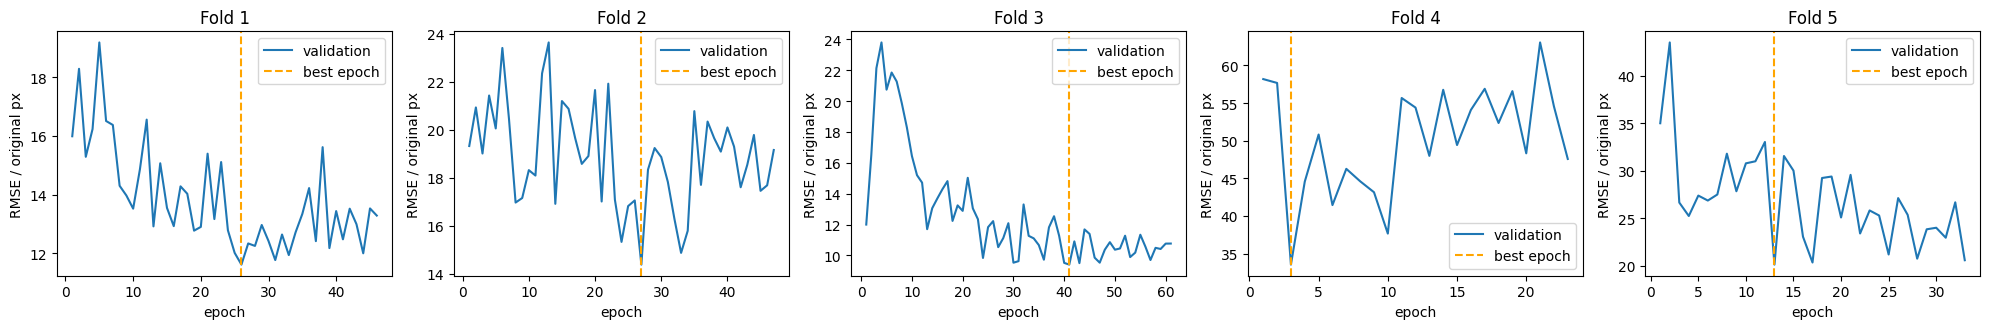

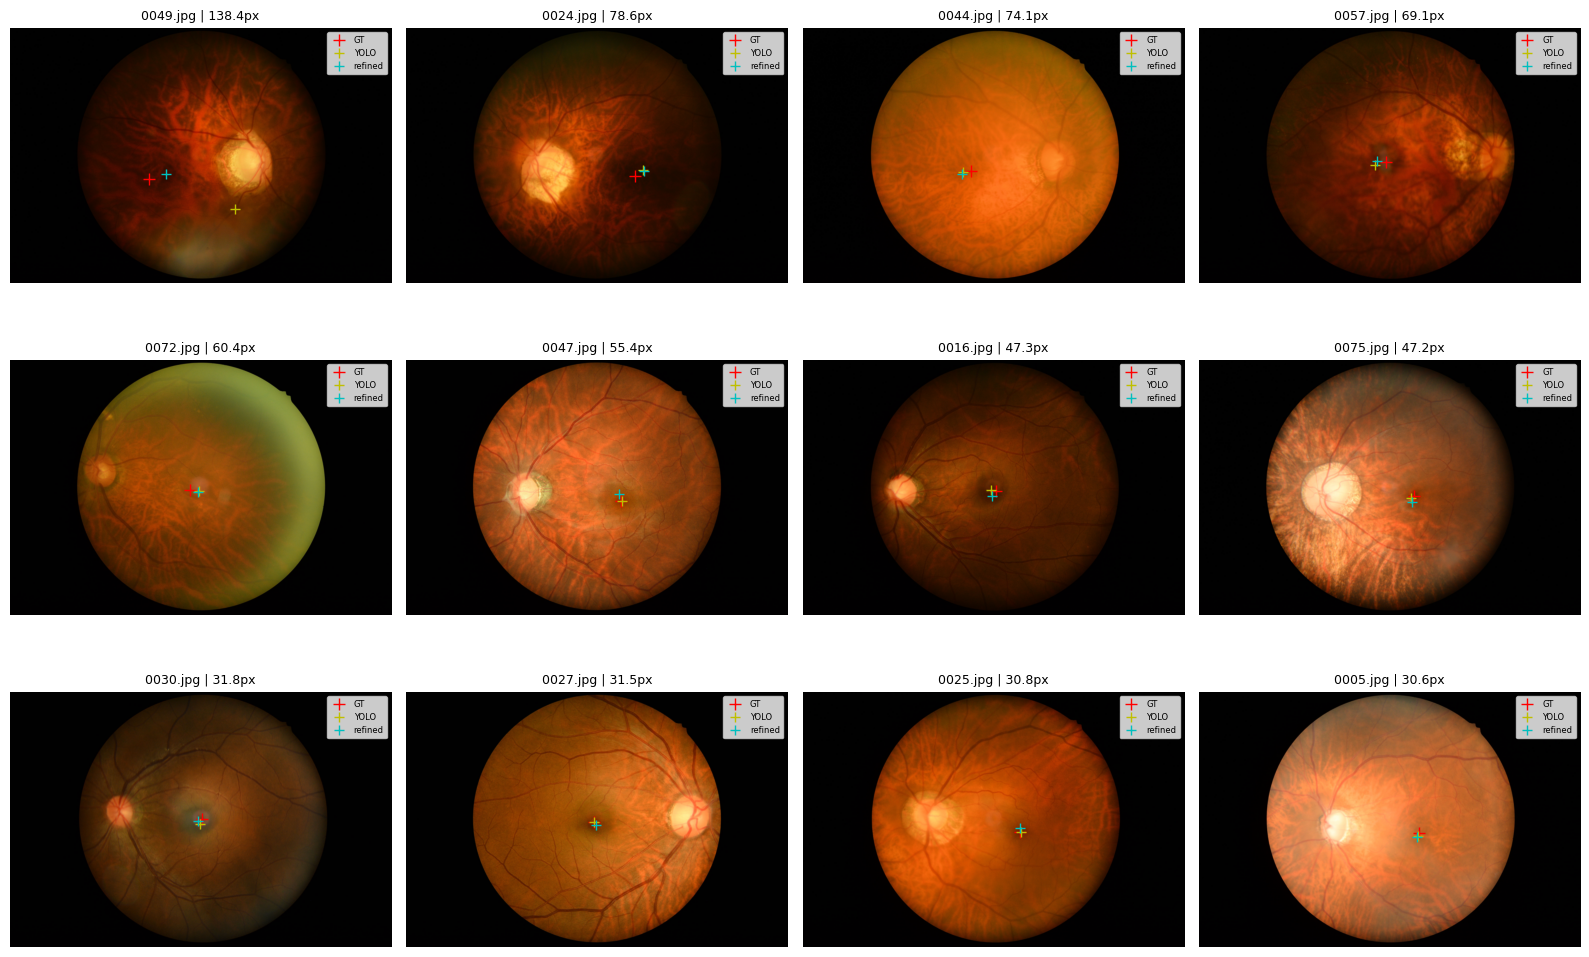

In [11]:
# 训练曲线和最差预测审核；不根据这些 GT 改变单张图的输出策略。
if RUN_CV:
    fig,axes=plt.subplots(1,len(records),figsize=(4*len(records),3.4),squeeze=False)
    for ax,record in zip(axes.flat,records):
        history=pd.read_csv(cv_dir/f'fold_{record["fold"]}'/'training_history.csv')
        ax.plot(history.epoch,history.val_rmse_px,label='validation')
        ax.axvline(record['best_epoch'],color='orange',linestyle='--',label='best epoch')
        ax.set_title(f'Fold {record["fold"]}'); ax.set_xlabel('epoch'); ax.set_ylabel('RMSE / original px'); ax.legend()
    plt.tight_layout(); fig.savefig(cv_dir/'validation_curves.png',dpi=130); plt.show(); plt.close(fig)
    worst=oof.assign(error=np.hypot(oof.final_x-oof.true_x,oof.final_y-oof.true_y)).nlargest(12,'error')
    fig,axes=plt.subplots(math.ceil(len(worst)/4),4,figsize=(16,3.5*math.ceil(len(worst)/4)),squeeze=False)
    for ax,r in zip(axes.flat,worst.itertuples(index=False)):
        with Image.open(r.path) as im: preview=im.convert('RGB'); preview.thumbnail((700,700))
        sx,sy=preview.width/r.width,preview.height/r.height; ax.imshow(preview)
        ax.plot(r.true_x*sx,r.true_y*sy,'r+',ms=8,label='GT')
        ax.plot(r.pred_x*sx,r.pred_y*sy,'y+',ms=7,label='YOLO')
        ax.plot(r.final_x*sx,r.final_y*sy,'c+',ms=7,label='refined')
        ax.set_title(f'{r.filename} | {r.error:.1f}px',fontsize=9); ax.legend(fontsize=6)
    for ax in axes.flat: ax.axis('off')
    plt.tight_layout(); fig.savefig(cv_dir/'worst_oof_predictions.png',dpi=130); plt.show(); plt.close(fig)


## 全量训练精修器

默认必须完整跑完五折，才允许自动确定全量 epoch。读取旧 CV 目录时检查训练配置和第一阶段配置一致。
全量训练继续使用 GT 加扰动生成训练裁剪，不使用第一阶段全数据 OOF 的误差来选择训练样本或窗口。

如果各折最佳 epoch 相差很大，或集中在训练上限，应先查看训练曲线再判断中位数是否合理；Notebook 会提示，不擅自改变轮次。需要额外实验时在开头设置覆盖值，记录到训练元数据。

In [12]:
full_path=Path(FINAL_REFINER_PATH) if FINAL_REFINER_PATH is not None else RUN_DIR/'full'/'full_model.pth'
if RUN_FULL_TRAIN:
    if FULL_EPOCHS_OVERRIDE is None:
        cv_settings=json.loads((cv_dir/'config.json').read_text(encoding='utf-8'))
        assert cv_settings['cfg']==CFG and cv_settings['stage1']==s1_config,'当前配置与 CV 不同，需重新验证'
        fm=pd.read_csv(cv_dir/'fold_metrics.csv')
        assert len(fm)==5 and set(fm.fold)=={1,2,3,4,5} and not fm.fold.duplicated().any()
        assert fm.val_n.sum()==len(df)
        epoch_values=fm.best_epoch.to_numpy(float)
        assert np.isfinite(epoch_values).all() and np.all(epoch_values==epoch_values.astype(int))
        assert np.all((epoch_values>=1)&(epoch_values<=CFG['epochs']))
        full_epochs=int(np.median(epoch_values)); rule='median_of_five_best_validation_epochs'
        if max(epoch_values)>=CFG['epochs'] or max(epoch_values)>3*min(epoch_values):
            print('提示：最佳 epoch 分散或达到上限，建议检查各折曲线。')
        print('各折最佳 epoch:',epoch_values.astype(int).tolist())
    else:
        assert int(FULL_EPOCHS_OVERRIDE)==FULL_EPOCHS_OVERRIDE
        full_epochs=int(FULL_EPOCHS_OVERRIDE); rule='explicit_override'; epoch_values=[]
        assert 1<=full_epochs<=CFG['epochs'],'保持同一学习率时间表，覆盖值不可超过 CV 上限'
    print('全量精修训练轮次:',full_epochs,'；训练图数:',len(df))
    if full_epochs<=CFG['warmup_epochs']: print('提示：所选轮次处于 head 预热期，骨干将保持冻结，与 CV 一致。')
    save_json(RUN_DIR/'full_training_plan.json',dict(epochs=full_epochs,rule=rule,
        fold_best_epochs=[int(x) for x in epoch_values],train_n=len(df),
        yolo_scope='existing fixed fold; not refit on all data'))
    full_path=RUN_DIR/'full'/'full_model.pth'
    fit(df,full_epochs,CFG['seed']+1000,RUN_DIR/'full')
    print('全量精修权重:',full_path)


提示：最佳 epoch 分散或达到上限，建议检查各折曲线。
各折最佳 epoch: [26, 27, 41, 3, 13]
全量精修训练轮次: 26 ；训练图数: 79
参数量: 2107042
epoch 1/26 train(aug)=57.53 full training
epoch 2/26 train(aug)=45.58 full training
epoch 3/26 train(aug)=41.15 full training
epoch 4/26 train(aug)=34.45 full training
epoch 5/26 train(aug)=30.44 full training
epoch 6/26 train(aug)=28.08 full training
epoch 7/26 train(aug)=25.27 full training
epoch 8/26 train(aug)=27.21 full training
epoch 9/26 train(aug)=25.34 full training
epoch 10/26 train(aug)=23.60 full training
epoch 11/26 train(aug)=21.59 full training
epoch 12/26 train(aug)=24.96 full training
epoch 13/26 train(aug)=25.78 full training
epoch 14/26 train(aug)=20.96 full training
epoch 15/26 train(aug)=19.90 full training
epoch 16/26 train(aug)=19.47 full training
epoch 17/26 train(aug)=19.37 full training
epoch 18/26 train(aug)=21.48 full training
epoch 19/26 train(aug)=21.74 full training
epoch 20/26 train(aug)=16.92 full training
epoch 21/26 train(aug)=18.00 full training
epoch 22

## 测试集预测与提交

加载开头指定的一折 YOLO 和全量精修器，全部测试图运行第二阶段；不使用测试 GT、不输出不可见占位 `(0,0)`。
YOLO 框返回的是 640 导出图上的边界坐标，仅除以缩放并加全局裁剪起点，不重复撤销 letterbox。

只想重新预测时，设置 `RUN_CV=False`、`RUN_FULL_TRAIN=False`，填写 `FINAL_REFINER_PATH`，从顶部运行即可。
配置不同会报错；使用已保存权重时需将顶部 CFG 改回训练配置。最终权重不是五折融合。

本次预测输出: /kaggle/working/fovea_mobilenet_offset/20261027_073418_6fe955/submission/20261027_082555_e65a6c0c44194088ba19ea0da5da42dc
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
0081.jpg local_detection (np.float64(1693.53), np.float64(1129.95))
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
0082.jpg local_detection (np.float64(1687.63), np.float64(1111.57))
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
0083.jpg local_detection (np.float64(1486.28), np.float64(1051.16))
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
0084.jpg local_detection (np.float64(1220.01), np.float64(1114.42))
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
0085.jpg local_detection (np.float64(1199.78), np.float64(987.87))
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quan

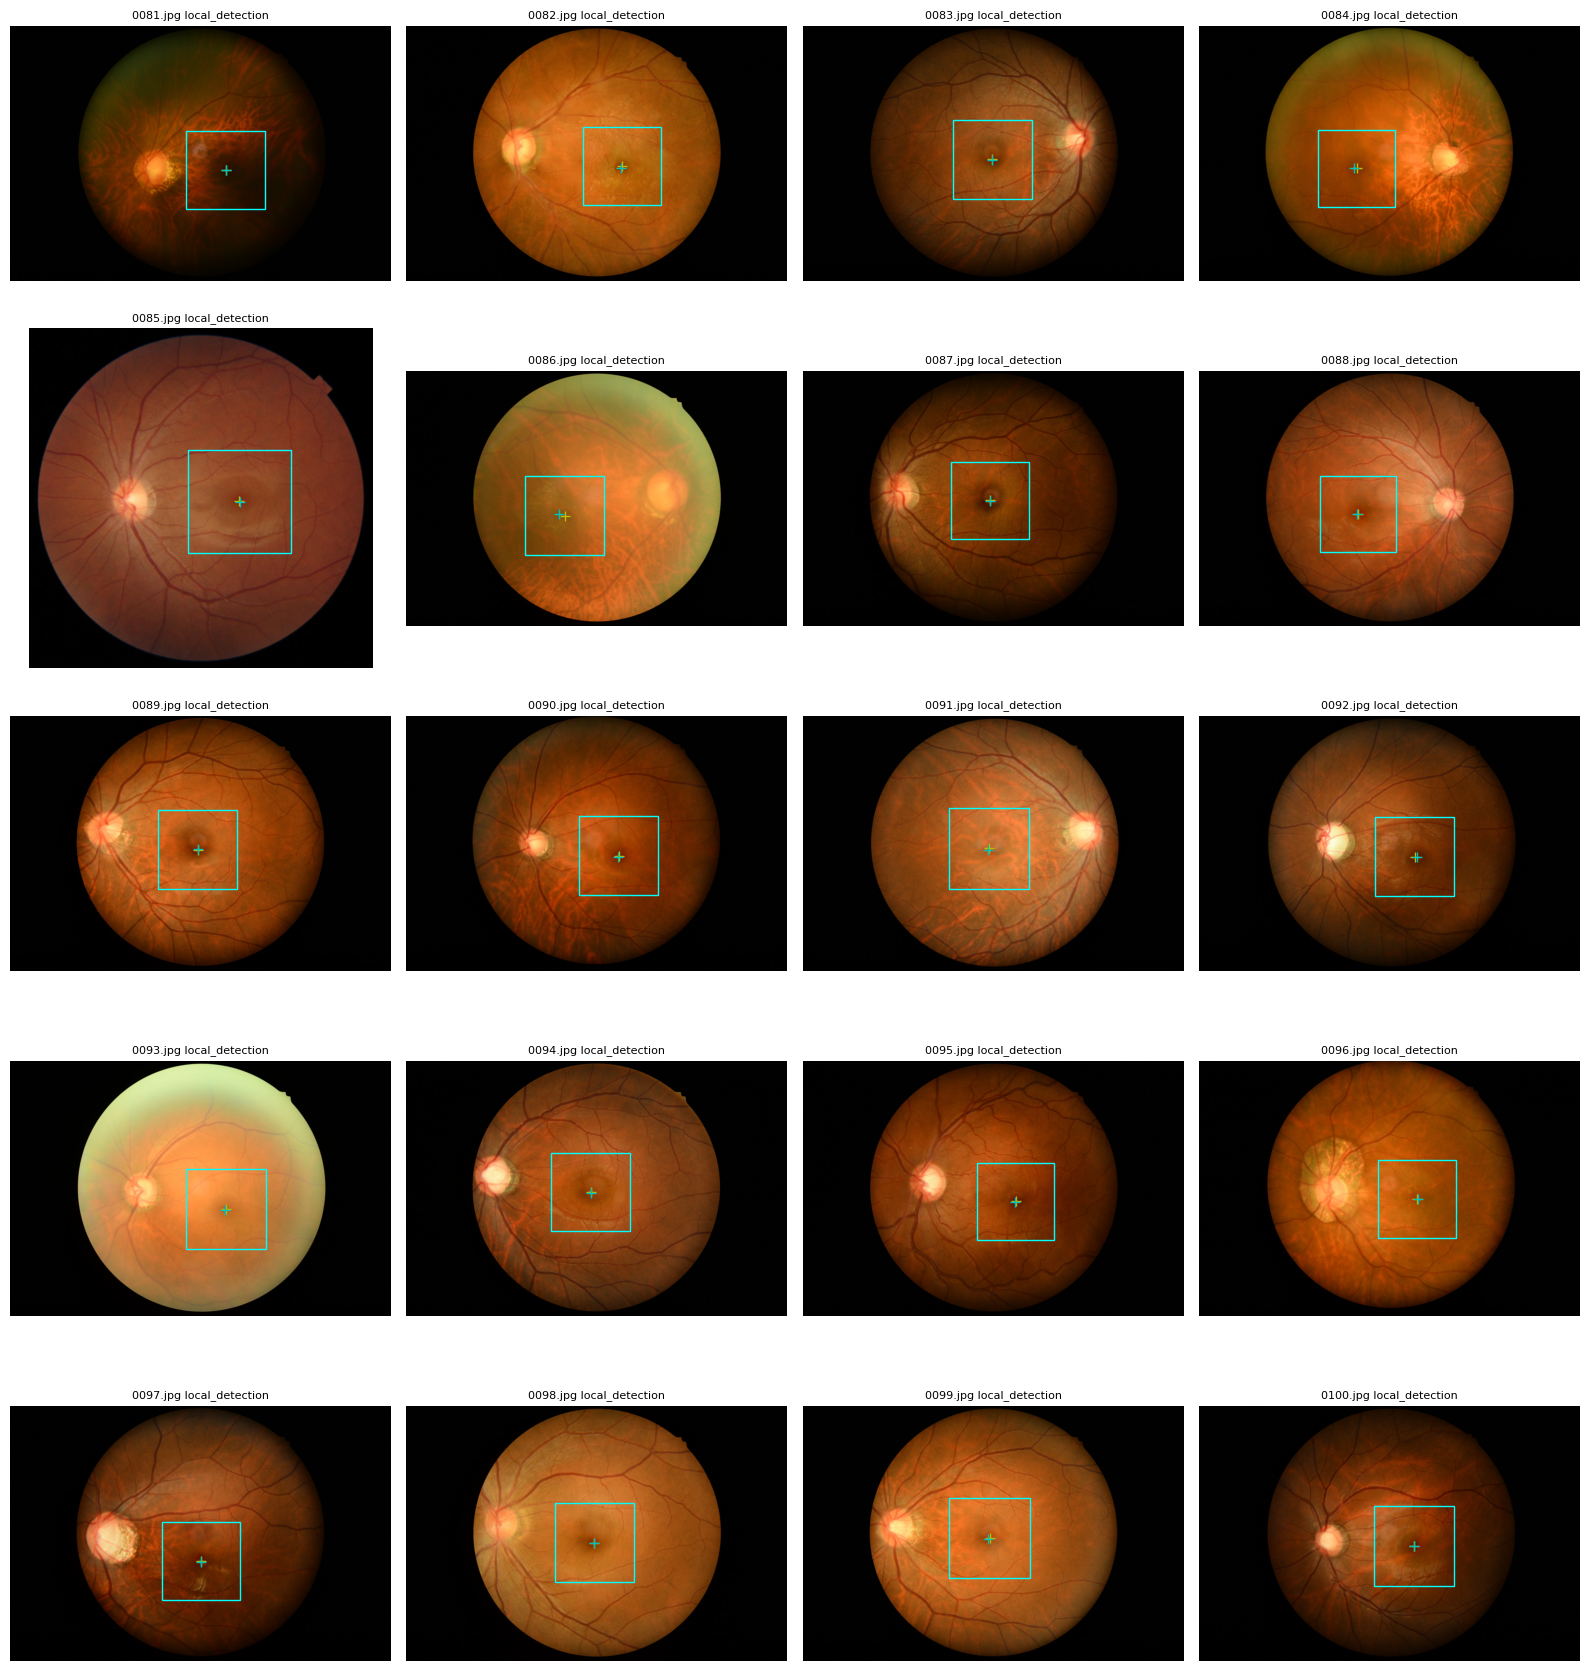

提交文件: /kaggle/working/fovea_mobilenet_offset/20261027_073418_6fe955/submission/20261027_082555_e65a6c0c44194088ba19ea0da5da42dc/submission.csv


,ImageID,value
0,81_Fovea_X,1693.531929
1,81_Fovea_Y,1129.951808
2,82_Fovea_X,1687.628449
3,82_Fovea_Y,1111.573586
4,83_Fovea_X,1486.284344
5,83_Fovea_Y,1051.159995
6,84_Fovea_X,1220.010041
7,84_Fovea_Y,1114.419363
8,85_Fovea_X,1199.778129
9,85_Fovea_Y,987.873197


In [18]:
def make_roi(cx,cy,bw,bh,global_side):
    roi=s1_config['roi_cfg']
    side=max(roi['expansion']*max(bw,bh),roi['min_side_fraction']*global_side)
    left,top=int(np.floor(cx-side/2)),int(np.floor(cy-side/2))
    size=int(np.ceil(max(cx+side/2-left,cy+side/2-top)))
    return left,top,size

@torch.no_grad()
def predict_test():
    if not full_path.is_file(): raise FileNotFoundError(full_path)
    yolo_path=STAGE1_DIR/f'fold_{FINAL_YOLO_FOLD}_best.pt'
    if not yolo_path.is_file(): raise FileNotFoundError(yolo_path)
    checkpoint=torch.load(full_path,map_location='cpu',weights_only=True)
    assert checkpoint['model_name']=='MobileNetV3SmallSpatialOffset'
    assert checkpoint['scope']=='all_79_unique_training_images','最终应加载全量精修器'
    assert checkpoint['cfg']==CFG and checkpoint['stage1_config']==s1_config,'预测配置与训练不一致'
    model=MobileNetOffset(pretrained=False).to(device)
    model.load_state_dict(checkpoint['model_state'],strict=True); model.eval()
    yolo=YOLO(str(yolo_path)); assert yolo.task=='detect'
    hints=set()
    for key in ('name','data'):
        stem=Path(str(yolo.ckpt.get('train_args',{}).get(key,''))).stem
        match=re.fullmatch(r'fold_(\d+)',stem)
        if match: hints.add(int(match.group(1)))
    if hints: assert hints=={FINAL_YOLO_FOLD},'YOLO 文件名与权重元数据的折号不一致'
    # 每次预测独立保存，支持中断后重跑，也保留此前提交。
    submission_root=RUN_DIR/'submission'
    submission_root.mkdir(parents=True,exist_ok=True)
    pred_dir=submission_root/(datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex)
    pred_dir.mkdir(exist_ok=False)
    (pred_dir/'prepared_test').mkdir()
    print('本次预测输出:',pred_dir)
    template=pd.read_csv(DATA_DIR/'sample_submission.csv',dtype={'ImageID':str})
    assert list(template.columns)==['ImageID','value'] and template.ImageID.notna().all()
    assert not template.ImageID.duplicated().any()
    keys=[]
    for key in template.ImageID:
        match=re.fullmatch(r'(\d+)_Fovea_([XY])',key)
        if not match: raise ValueError(f'不支持的模板编号: {key}')
        keys.append((int(match.group(1)),match.group(2)))
    assert len(set(keys))==len(keys)
    paths={}
    for path in sorted((DATA_DIR/'test').iterdir()):
        if path.suffix.lower() not in {'.jpg','.jpeg','.png'}: continue
        assert path.stem.isdigit() and int(path.stem) not in paths
        paths[int(path.stem)]=path
    assert len(paths)==EXPECTED_TEST_COUNT
    assert set(keys)=={(i,axis) for i in paths for axis in ('X','Y')}
    records=[]; scfg=s1_config['cfg']
    yolo_device=str(device) if device.type=='cpu' else (device.index if device.index is not None else 0)
    for image_id,path in paths.items():
        with Image.open(path) as im: image=im.convert('RGB')
        crop=detect_fundus_square(image,s1_config['crop_cfg'])
        left,top,side=crop['crop_left'],crop['crop_top'],crop['crop_side']
        size=int(scfg['image_size']); scale=size/side
        prepared=pred_dir/'prepared_test'/f'{image_id:04d}.png'
        image.crop((left,top,left+side,top+side)).resize((size,size),Image.Resampling.BILINEAR).save(prepared)
        result=yolo.predict(str(prepared),imgsz=size,conf=scfg['predict_conf'],iou=scfg['nms_iou'],
            max_det=scfg['max_det'],device=yolo_device,classes=[0],half=False,augment=False,save=False,verbose=False)[0]
        assert tuple(result.orig_shape)==(size,size)
        candidates=[]
        if result.boxes is not None:
            for bb,conf in zip(result.boxes.xyxy.cpu().numpy(),result.boxes.conf.cpu().numpy()):
                if np.isfinite(bb).all() and np.isfinite(conf) and bb[2]>bb[0] and bb[3]>bb[1]:
                    candidates.append((float(conf),bb))
        record=dict(image_id=image_id,filename=path.name,path=str(path),width=image.width,height=image.height,
                    detected=bool(candidates),confidence=np.nan,n_candidates=len(candidates),**crop)
        if candidates:
            conf,bb=max(candidates,key=lambda t:t[0]); bb=bb/scale+np.array([left,top,left,top])
            center=np.clip((bb[:2]+bb[2:])/2,[0,0],[image.width-1,image.height-1])
            record.update(confidence=conf,pred_x=float(center[0]),pred_y=float(center[1]),
                pred_xmin=float(bb[0]),pred_ymin=float(bb[1]),pred_xmax=float(bb[2]),pred_ymax=float(bb[3]))
        else:
            record.update(pred_x=np.nan,pred_y=np.nan,pred_xmin=np.nan,pred_ymin=np.nan,pred_xmax=np.nan,pred_ymax=np.nan)
        weak=not candidates or record['confidence']<CFG['low_confidence_threshold']
        if weak: el,et,es=left,top,side
        else: el,et,es=make_roi(*center,bb[2]-bb[0],bb[3]-bb[1],side)
        tensor=tile_tensor(image,el,et,es)[None].to(device)
        offset=model(tensor.float())[0].cpu().numpy()
        xy=np.clip(offset_to_point(offset,el,et,es),[0,0],[image.width-1,image.height-1])
        record.update(eval_left=el,eval_top=et,eval_side=es,eval_mode='global_fallback' if weak else 'local_detection',
                      offset_x=float(offset[0]),offset_y=float(offset[1]),final_x=float(xy[0]),final_y=float(xy[1]))
        records.append(record); pd.DataFrame(records).to_csv(pred_dir/'test_predictions.csv',index=False)
        print(path.name,record['eval_mode'],tuple(np.round(xy,2)))
    predictions=pd.DataFrame(records); lookup=predictions.set_index('image_id')
    assert len(predictions)==EXPECTED_TEST_COUNT and lookup.index.is_unique
    assert np.isfinite(lookup[['final_x','final_y']].to_numpy()).all()
    submission=template.copy()
    submission['value']=[float(lookup.loc[i,'final_x' if axis=='X' else 'final_y']) for i,axis in keys]
    target=pred_dir/'submission.csv'; submission.to_csv(target,index=False)
    written=pd.read_csv(target,dtype={'ImageID':str})
    assert list(written.columns)==['ImageID','value'] and written.ImageID.equals(template.ImageID)
    assert len(written)==2*EXPECTED_TEST_COUNT and np.isfinite(written.value.to_numpy()).all()
    save_json(pred_dir/'prediction_config.json',dict(yolo_fold=FINAL_YOLO_FOLD,
        yolo_weights=str(yolo_path),yolo_sha256=sha256(yolo_path),
        refiner_weights=str(full_path),refiner_sha256=sha256(full_path),
        refiner_full_epochs=int(checkpoint['epoch']),cfg=CFG,stage1=s1_config,
        scope='full-data refiner plus existing single-fold YOLO; no ensemble'))
    fig,axes=plt.subplots(math.ceil(len(predictions)/4),4,figsize=(16,3.5*math.ceil(len(predictions)/4)),squeeze=False)
    for ax,r in zip(axes.flat,predictions.itertuples(index=False)):
        with Image.open(r.path) as im: preview=im.convert('RGB'); preview.thumbnail((700,700))
        sx,sy=preview.width/r.width,preview.height/r.height; ax.imshow(preview)
        if r.detected: ax.plot(r.pred_x*sx,r.pred_y*sy,'y+',ms=7)
        ax.plot(r.final_x*sx,r.final_y*sy,'c+',ms=7)
        ax.add_patch(Rectangle((r.eval_left*sx,r.eval_top*sy),r.eval_side*sx,r.eval_side*sy,fill=False,edgecolor='cyan'))
        ax.set_xlim(0,preview.width); ax.set_ylim(preview.height,0); ax.set_title(r.filename+' '+r.eval_mode,fontsize=8)
    for ax in axes.flat: ax.axis('off')
    plt.tight_layout(); fig.savefig(pred_dir/'test_previews.png',dpi=130); plt.show(); plt.close(fig)
    print('提交文件:',target); display(submission)
    return predictions

if RUN_SUBMISSION:
    test_predictions=predict_test()



## 运行后保留的结果

- `cv/fold_metrics.csv`：每折最佳 epoch 和原图 RMSE，用于确定全量轮次。
- `cv/oof_predictions.csv`、`cv/cv_summary.json`：完整链路与 YOLO 基线对照，含局部/全局子集指标。
- `cv/fold_*/training_history.csv`、`best.pth`：训练曲线数据、每折模型。
- `full_training_plan.json`、`full/full_model.pth`：轮次选择依据、79 张不同训练图训练的精修器。
- `submission/submission.csv`：唯一上传到比赛的文件；`test_predictions.csv` 和预览图用于诊断。

先看 OOF 是否改善，再判断提交是否值得保留。若新模型退化，不应只凭模型小或全量训练就认定它更好。全量精修器没有独立验证分数，五折 OOF 是它的训练方案估计，并非这个最终模型的实测成绩。